### Credit Card Fraud Project

We are going to be using a credit card fraud detection dataset from Kaggle. https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud 

In [169]:
import pandas as pd
import matplotlib.pyplot as plt

In [170]:
#Load the CSV and inspect the data
df = pd.read_csv('data/creditcard_csv.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,'0'
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,'0'
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,'0'
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,'0'
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,'0'


In [171]:
#Inspect column counts and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [172]:
#Convert the class column to a integer
df['Class'].unique()
df['Class'] = df['Class'].str.replace("'", '').astype(int)



In [173]:
#We want to see what the expected value for the 'Class' column is. This will tell in general the % of fraud cases are there
df.describe()                                                 

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.596686e-16,-3.576577e-16,2.618565e-16,4.473116e-15,5.109395e-16,1.686100e-15,-3.657409e-16,-1.221465e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


### Task 2 - What makes something a fraudulent?
1. Very small transaction (testing if a card works)
2. Very large transaction amounts (after seeing a card works, spending large amounts)
3. Time of the transaction (ie night vs day, 3pm vs 1am)
4. Lastly, and more specific to the data, a very positive or very negative values (values are centered around 0!)


First step will be analyzing small and large transactions


In [174]:
#Create a column small transactions, anything less half  the 25th percentile will be considered small
q25 = df['Amount'].quantile(0.25) 
q75 = df['Amount'].quantile(0.75)
df['SmallTransaction'] = df['Amount'] <= q25 / 2

#Similarly for large transactions but we will use twice the 75th percentile
df['LargeTransaction'] = df['Amount'] >= q75 * 2

#All other cases will be considered a normal transaction
df['RegularTransaction'] = ~(df['LargeTransaction'] | df['SmallTransaction'])

df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V24,V25,V26,V27,V28,Amount,Class,SmallTransaction,LargeTransaction,RegularTransaction
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,False,False,True
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,True,False,False
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,False,True,False
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,False,False,True
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,False,False,True


In [175]:
#Now, group by the class label on each type of transaction and get the percentage of classes labeled as fraud
cols = ['SmallTransaction', 'LargeTransaction', 'RegularTransaction']
summary = df.groupby('Class')[cols].sum()
summary.head()

pct = (summary.iloc[1] / summary.iloc[0]) * 100 #We should get VERY low percentages
print(pct)


SmallTransaction      0.383127
LargeTransaction      0.256249
RegularTransaction    0.098149
dtype: float64


In [176]:
#Create a column for the hour and the day (0/1 for day column)
df['Hour'] = (df['Time'] // 3600) % 24 #24-hour clock 
df['Day'] = (df['Time'] // 86400) % 2

print(df['Hour'].tail(2))
print(df['Day'].tail(2))

284805    23.0
284806    23.0
Name: Hour, dtype: float64
284805    1.0
284806    1.0
Name: Day, dtype: float64


### Task 3: Plotting the data
1. See when tranactions occur, and see if transactions labeled as fraud occur more at specific times


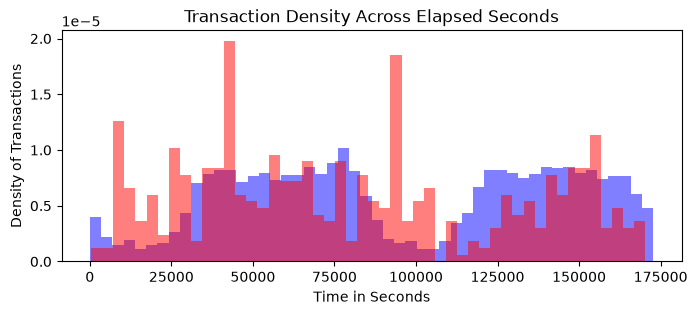

In [178]:
legit = df[df['Class'] == 0]
fraud = df[df['Class'] == 1]

#Histogram for the percent of transactions at a given moment in seconds
plt.figure(figsize=(8,3))
plt.hist(
    legit['Time'],
    bins=50,
    alpha=0.5,
    label='Legitimate',
    density=True,
    color='blue')

#overlay the fraud class over the same histogram
plt.hist(
    fraud['Time'],
    bins=50,
    alpha=0.5,
    label='Legitimate',
    density=True,
    color='red')
plt.title('Transaction Density Across Elapsed Seconds')
plt.xlabel('Time in Seconds')
plt.ylabel('Density of Transactions')
plt.show()